# 02 - Prétraitement des coupes HDF5

Le dataset disponible contient des coupes 2D HDF5. Les quatre modalités de `image` sont normalisées par coupe et les trois canaux de `mask` sont fusionnés en une cible binaire.

In [1]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = REPO_ROOT / "data/raw/data"
OUTPUT_ROOT = REPO_ROOT / "results/preprocessed_h5"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
files = sorted(DATA_ROOT.glob("*.h5"))
if not files:
    raise FileNotFoundError(f"Aucun fichier HDF5 dans {DATA_ROOT}")
print(f"Coupes disponibles: {len(files)}")

Coupes disponibles: 57195


In [6]:
def volume_id(path: Path) -> str:
    return path.stem.rsplit("_slice_", 1)[0]

def normalize_channels(image: np.ndarray) -> np.ndarray:
    image = np.asarray(image, dtype=np.float32)
    result = np.zeros_like(image)
    for channel in range(image.shape[-1]):
        values = image[:, :, channel]
        mask = values != 0
        if np.any(mask):
            result[:, :, channel][mask] = (values[mask] - values[mask].mean()) / max(values[mask].std(), np.finfo(np.float32).eps)
    return result

volume_ids = sorted({volume_id(path) for path in files})
rng = np.random.default_rng(42)
rng.shuffle(volume_ids)
cut_train = int(0.7 * len(volume_ids))
cut_val = int(0.85 * len(volume_ids))
splits = {"train": volume_ids[:cut_train], "val": volume_ids[cut_train:cut_val], "test": volume_ids[cut_val:]}
(OUTPUT_ROOT / "splits.json").write_text(__import__("json").dumps(splits, indent=2), encoding="utf-8")
print({name: len(values) for name, values in splits.items()})

{'train': 258, 'val': 55, 'test': 56}


Image: (240, 240, 4) Mask: (240, 240, 3) Tumor pixels: 0


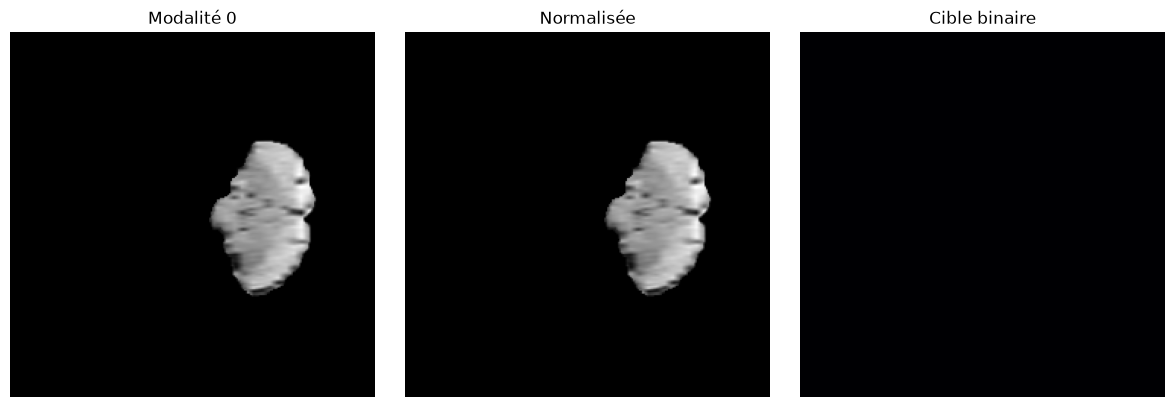

In [7]:
sample = files[len(files) // 2]
with h5py.File(sample, "r") as handle:
    image = handle["image"][:]
    mask = handle["mask"][:]
normalized = normalize_channels(image)
target = mask.any(axis=-1)
print("Image:", image.shape, "Mask:", mask.shape, "Tumor pixels:", int(target.sum()))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image[:, :, 0], cmap="gray"); axes[0].set_title("Modalité 0")
axes[1].imshow(normalized[:, :, 0], cmap="gray"); axes[1].set_title("Normalisée")
axes[2].imshow(target, cmap="magma"); axes[2].set_title("Cible binaire")
for axis in axes: axis.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "h5_preprocessing_example.png", dpi=150)
plt.show()